# Linear Regression for DDoS Detection (Binary Classification)

In this notebook, we convert the multi-class DDoS dataset into a **binary dataset**:
- **`0`**: `BENIGN` (Normal traffic)
- **`1`**: `DDOS` (All DDoS attack variants)

Since **Linear Regression** requires numeric targets and models continuous values, we map the labels to integers (`0` and `1`) and use a decision threshold (e.g., $0.5$) to classify predictions (Linear Probability Model).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
)

## 1. Load Datasets

In [2]:
train_df = pd.read_csv('TrainingSet.csv')
test_df = pd.read_csv('TestingSet.csv')

print(f"Training set shape: {train_df.shape}")
print(f"Testing set shape:  {test_df.shape}")

Training set shape: (16000, 40)
Testing set shape:  (4000, 40)


## 2. Inspect Original Target Distribution
Notice the dataset contains `BENIGN` plus multiple specific DDoS attack categories.

In [3]:
print("--- Original Training Target Distribution ---")
print(train_df['Target'].value_counts())

print("\n--- Original Testing Target Distribution ---")
print(test_df['Target'].value_counts())

--- Original Training Target Distribution ---
Target
BENIGN                     7945
DDOS-RSTFINFLOOD           1188
DDOS-TCP_FLOOD             1166
DDOS-ICMP_FLOOD            1153
DDOS-UDP_FLOOD             1149
DDOS-SYN_FLOOD             1140
DDOS-SYNONYMOUSIP_FLOOD    1137
DDOS-PSHACK_FLOOD          1122
Name: count, dtype: int64

--- Original Testing Target Distribution ---
Target
BENIGN                     2055
DDOS-PSHACK_FLOOD           307
DDOS-SYNONYMOUSIP_FLOOD     291
DDOS-SYN_FLOOD              288
DDOS-UDP_FLOOD              280
DDOS-ICMP_FLOOD             276
DDOS-TCP_FLOOD              263
DDOS-RSTFINFLOOD            240
Name: count, dtype: int64


## 3. Convert Target to Binary (0 = BENIGN, 1 = DDOS)

We convert all DDoS attack classes into `1` and `BENIGN` into `0`.

In [4]:
# Convert Target to binary: 0 for BENIGN, 1 for any DDoS attack type
train_df['Target'] = (train_df['Target'] != 'BENIGN').astype(int)
test_df['Target'] = (test_df['Target'] != 'BENIGN').astype(int)

print("--- Binary Training Target Distribution ---")
print(train_df['Target'].value_counts())

print("\n--- Binary Testing Target Distribution ---")
print(test_df['Target'].value_counts())

--- Binary Training Target Distribution ---
Target
1    8055
0    7945
Name: count, dtype: int64

--- Binary Testing Target Distribution ---
Target
0    2055
1    1945
Name: count, dtype: int64


## 4. Dataset Summary Report

In [5]:
def data_report(data):
    data = pd.DataFrame(
        {
            "dtype": data.dtypes.astype(str),
                    # Show the data type of each column (e.g., int, float, object)
            
                    "missing": data.isna().sum(),
                    # Count the number of missing values (NaN) in each column
            
                    "missing_%": (data.isna().mean() * 100).round(2),
                    # Calculate the percentage of missing values in each column
            
                    "unique": data.nunique(dropna=False),
                    # Count the number of unique values in each column
                    # dropna=False means that NaN is also counted as a unique value
            
                    "duplicates": data.duplicated().sum()
                    # Count the total number of duplicated rows in the dataset
         }
    )
    return data

train_report = data_report(train_df)
print(train_report)

test_report = data_report(test_df)
print(test_report)

train_df.describe()
test_df.describe()

                   dtype  missing  missing_%  unique  duplicates
Header_Length    float64        0       0.00     223         108
Protocol Type      int64        0       0.00       4         108
Time_To_Live     float64        0       0.00    1583         108
Rate             float64        2       0.01   13514         108
fin_flag_number  float64        0       0.00      20         108
syn_flag_number  float64        0       0.00      48         108
rst_flag_number  float64        0       0.00      66         108
psh_flag_number  float64        0       0.00      70         108
ack_flag_number  float64        0       0.00      88         108
ece_flag_number  float64        0       0.00       4         108
cwr_flag_number  float64        0       0.00       2         108
ack_count          int64        0       0.00      83         108
syn_count          int64        0       0.00      46         108
fin_count          int64        0       0.00      19         108
rst_count          int64 

,Header_Length,Protocol Type,Time_To_Live,Rate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,...,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Variance,Target
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,...,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.0000,4.000000e+03,4000.000000
mean,21.487290,6.883750,90.511387,17348.006654,0.065723,0.150982,0.063705,0.159575,0.490177,0.000200,...,6028.108500,94.004000,907.138750,337.392302,283.115251,337.392302,0.004711,53.7375,3.815405e+05,0.486250
std,9.029156,3.816527,44.399276,28232.285594,0.237068,0.348303,0.238453,0.271442,0.439660,0.004997,...,4658.567905,209.367997,1690.759656,534.138147,549.055248,534.138147,0.007828,44.9906,1.621445e+06,0.499873
min,0.000000,0.000000,31.200000,16.876130,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,480.000000,60.000000,60.000000,60.000000,0.000000,60.000000,0.000002,2.0000,0.000000e+00,0.000000
25%,19.920000,6.000000,64.000000,158.524633,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,2196.750000,60.000000,60.000000,60.000000,0.000000,60.000000,0.000035,10.0000,0.000000e+00,0.000000
50%,20.000000,6.000000,64.000000,5037.599049,0.000000,0.000000,0.000000,0.000000,0.600000,0.000000,...,6000.000000,60.000000,116.000000,66.000000,6.161659,66.000000,0.000214,10.0000,3.796985e+01,0.000000
75%,29.600000,6.000000,100.825000,29017.312195,0.000000,0.000000,0.000000,0.200000,1.000000,0.000000,...,6023.000000,66.000000,1494.000000,278.050000,443.805758,278.050000,0.007169,100.0000,1.969636e+05,1.000000
max,51.600000,17.000000,250.100000,524288.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.200000,...,39744.000000,2922.000000,20338.000000,3974.400000,6478.256610,3974.400000,0.060816,100.0000,4.196781e+07,1.000000


## 5. Handle Missing Values and Duplicates
Some columns (e.g., `Rate`, `Std`) contain a few empty entries in the training set that parse as NaN. Linear regression requires finite numeric values, so they are filled with the column median. Duplicate rows are then removed from the training set.

In [6]:
# Check for missing values
missing_train = train_df.isna().sum().sum()
missing_test = test_df.isna().sum().sum()
print(f"Missing values in Train: {missing_train}, in Test: {missing_test}")

# set the missing values to the median of the respective columns
train_df_cleaned = train_df.fillna(train_df.median())
test_df_cleaned = test_df.fillna(test_df.median())

# check for duplicates in the training set
duplicates_train = train_df_cleaned.duplicated().sum()
print(f"Duplicate rows in Train: {duplicates_train}")
# Remove duplicates rows from the training set
train_df_cleaned = train_df_cleaned.drop_duplicates()

# after cleaning check the shape of the cleaned datasets
print(f"Cleaned Training set shape: {train_df_cleaned.shape}")
print(f"Cleaned Testing set shape:  {test_df_cleaned.shape}")

Missing values in Train: 6, in Test: 0
Duplicate rows in Train: 108
Cleaned Training set shape: (15892, 40)
Cleaned Testing set shape:  (4000, 40)


## 6. Check if the Dataset Follows a Linear Pattern
Correlation of every feature with the binary target, followed by scatter/regression plots of the top features.

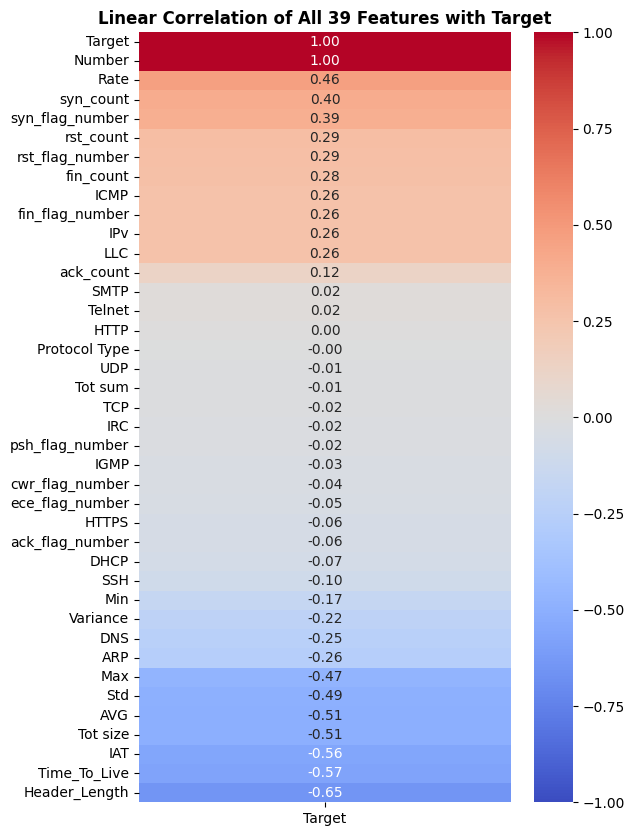

In [7]:
# 1. Calculate correlations between all features and your target variable
correlations = train_df_cleaned.corr()["Target"].sort_values(
    ascending=False
)

# 2. Convert to a DataFrame and plot the top linearly related features
plt.figure(figsize=(6, 10))
sns.heatmap(
    correlations.to_frame(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
)

plt.title("Linear Correlation of All 39 Features with Target", weight="bold")
plt.show()


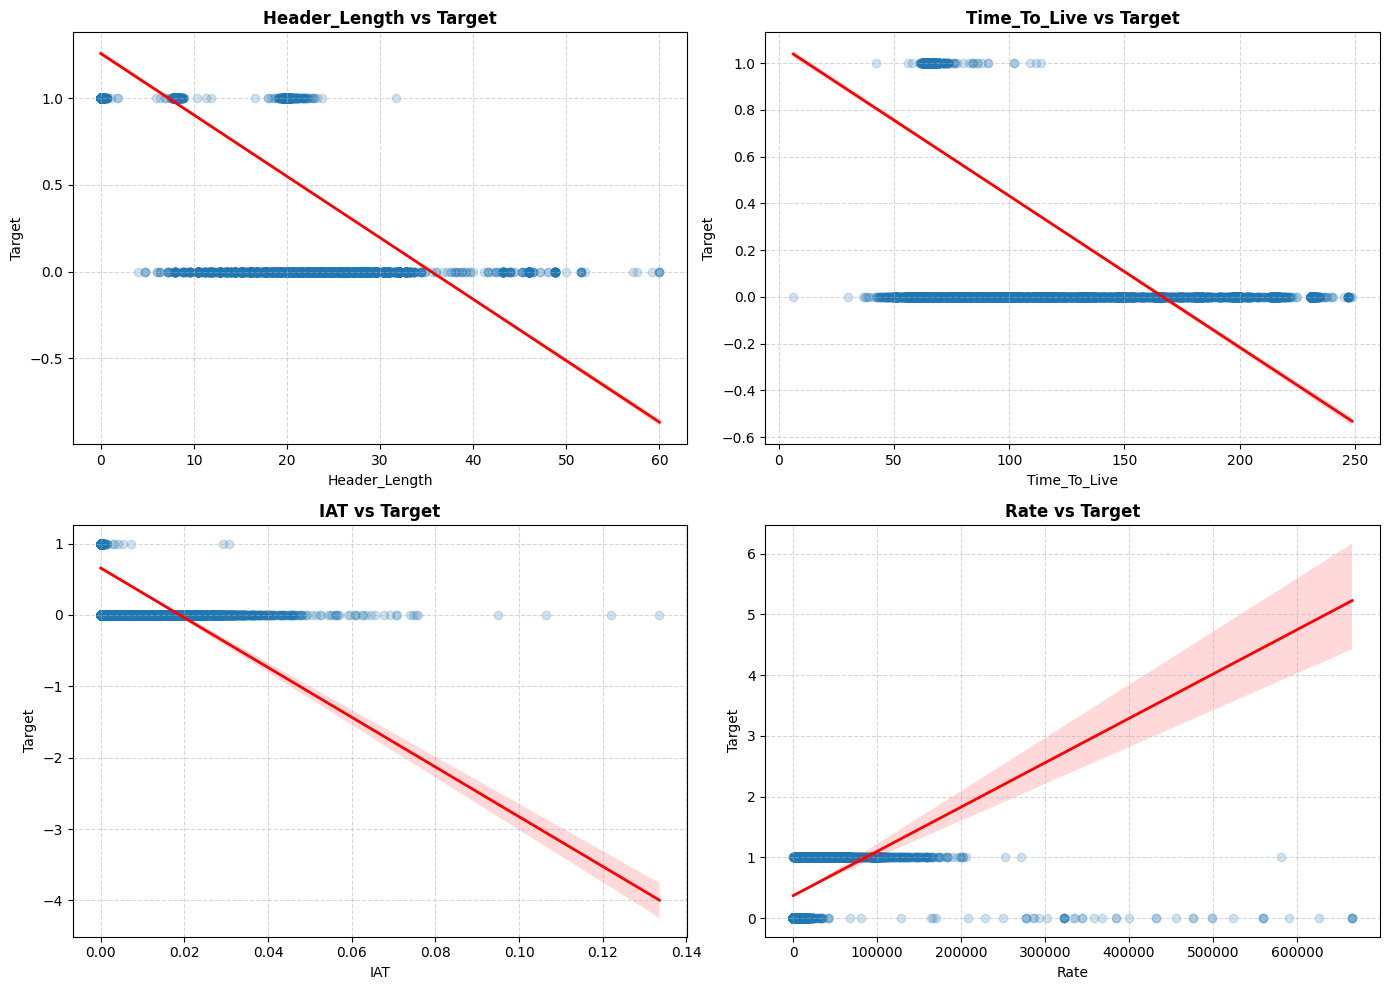

In [8]:
# The 4 features with the strongest linear correlation scores
top_features = ["Header_Length", "Time_To_Live", "IAT", "Rate"]
target = "Target"

# Create a 2x2 grid of plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()  # Flatten into a 1D array to loop easily

for i, feature in enumerate(top_features):
    sns.regplot(
        data=train_df_cleaned,
        x=feature,
        y=target,
        ax=axes[i],
        scatter_kws={"alpha": 0.2, "color": "#1f77b4"},
        line_kws={"color": "red", "linewidth": 2},
    )
    axes[i].set_title(f"{feature} vs Target", fontsize=12, weight="bold")
    axes[i].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 7. Data Leakage Check: the `Number` Feature
`Number` showed a correlation of ~1 with the target. It takes almost only two values (10 and 100), which looks like a dataset-collection artifact rather than real traffic behavior. It is dropped here, **before** the features are separated, so the model never sees it.

In [9]:
# 'Number' has a correlation of ~1 with Target -> likely data leakage
print(train_df_cleaned['Number'].value_counts())
print(train_df_cleaned['Number'].describe())
train_df_cleaned = train_df_cleaned.drop(columns=["Number"])
test_df_cleaned = test_df_cleaned.drop(columns=["Number"])


Number
100    7944
10     7933
1         2
6         2
9         1
68        1
17        1
48        1
3         1
8         1
76        1
79        1
96        1
53        1
43        1
Name: count, dtype: int64
count    15892.000000
mean        55.011578
std         44.995678
min          1.000000
25%         10.000000
50%         77.500000
75%        100.000000
max        100.000000
Name: Number, dtype: float64


## 8. Separate Features (X) and Target (y)

In [10]:
X_train = train_df_cleaned.drop(columns=['Target'])
y_train = train_df_cleaned['Target']

X_test = test_df_cleaned.drop(columns=['Target'])
y_test = test_df_cleaned['Target']

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

X_train shape: (15892, 38), y_train shape: (15892,)
X_test shape: (4000, 38), y_test shape: (4000,)


## 9. Train Linear Regression Model

In [11]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully.")
print(f"Intercept: {model.intercept_:.4f}")

Model trained successfully.
Intercept: 0.0550


## 10. Predict & Evaluate
Since Linear Regression outputs continuous predictions, we apply a decision threshold to get class labels (0.7 in the code below; the threshold sweep in Section 11 shows identical accuracy for 0.5, 0.6 and 0.7):
- If $\hat{y} \ge$ threshold $\rightarrow 1$ (DDoS)
- If $\hat{y} <$ threshold $\rightarrow 0$ (Benign)

In [13]:
# Continuous predictions
y_pred_cont = model.predict(X_test)

# Apply decision threshold
y_pred_binary = (y_pred_cont >= 0.5).astype(int)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred_binary))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_binary))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_binary, target_names=['BENIGN', 'DDOS']))
# AUROC
auroc = roc_auc_score(y_test, y_pred_cont)
print(f"AUROC: {auroc}")

Accuracy: 0.99975

Confusion Matrix:
[[2055    0]
 [   1 1944]]

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00      2055
        DDOS       1.00      1.00      1.00      1945

    accuracy                           1.00      4000
   macro avg       1.00      1.00      1.00      4000
weighted avg       1.00      1.00      1.00      4000

AUROC: 0.9999852388368704


## 11. Sanity Checks: Why Is the Score So High?
Checks run on the trained model to see whether the near-perfect score comes from leakage or from an easy dataset:
1. Single-feature AUROC: how much does one column give away?
2. Exact train/test row overlap
3. Depth-1 decision tree: how simple can a model be and still win?
4. Threshold sweep (diagnostic only, not used to pick the threshold)
5. Ablation: retrain without the 5 most separable features

In [14]:
feats = list(X_train.columns)
print("Number still in features:", "Number" in feats)

# 1. Single-feature AUROC on test: how much does one column give away?
rows = []
for f in feats:
    a = roc_auc_score(y_test, X_test[f])
    rows.append((f, max(a, 1 - a)))
single = pd.DataFrame(rows, columns=["feature", "auc"]).sort_values("auc", ascending=False)
print("\nTop single-feature AUROC:\n", single.head(10).to_string(index=False))

# 2. Exact train/test row overlap
train_keys = set(map(tuple, X_train.round(6).values))
overlap = sum(tuple(r) in train_keys for r in X_test.round(6).values)
print(f"\nTest rows that also appear exactly in train: {overlap} / {len(X_test)}")

# 3. How simple can a model be and still win?
stump = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X_train, y_train)
print("Depth-1 tree accuracy:", accuracy_score(y_test, stump.predict(X_test)))
print("Stump splits on:", feats[stump.tree_.feature[0]])

# 4. Threshold sweep (diagnostic only, don't pick a threshold from test)
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    print(f"threshold {t}: acc = {accuracy_score(y_test, (y_pred_cont >= t).astype(int)):.5f}")

# 5. Ablation: drop the top-5 most separable features and retrain
drop = single.feature.head(5).tolist()
keep = [f for f in feats if f not in drop]
m2 = LinearRegression().fit(X_train[keep], y_train)
p2 = m2.predict(X_test[keep])
print(f"\nWithout {drop}:")
print("  accuracy:", accuracy_score(y_test, (p2 >= 0.5).astype(int)))
print("  AUROC:   ", roc_auc_score(y_test, p2))

Number still in features: False

Top single-feature AUROC:
         feature      auc
       Tot size 0.997295
            AVG 0.997295
            IAT 0.991053
           Rate 0.989083
            Max 0.976423
            Std 0.960666
       Variance 0.960666
          HTTPS 0.942590
  Header_Length 0.899863
ack_flag_number 0.882158

Test rows that also appear exactly in train: 132 / 4000
Depth-1 tree accuracy: 0.99175
Stump splits on: AVG
threshold 0.3: acc = 0.99500
threshold 0.4: acc = 0.99875
threshold 0.5: acc = 0.99975
threshold 0.6: acc = 0.99975
threshold 0.7: acc = 0.99975

Without ['Tot size', 'AVG', 'IAT', 'Rate', 'Max']:
  accuracy: 0.993
  AUROC:    0.9999979984863554


## 12. Conclusion

**Setup.** Binary classification (0 = BENIGN, 1 = DDoS, all seven flood types merged) on 16,000 training rows and 4,000 test rows, 40 columns. Training data: 6 missing values filled with the median, 108 duplicate rows removed (15,892 left). Classes are balanced (train 8,055 DDoS / 7,945 benign; test 1,945 / 2,055). The `Number` column was removed as a leakage risk, leaving 38 features.

**Result.** The Linear Probability Model reaches **accuracy 0.99975** on the test set: 1 error in 4,000 (0 false positives out of 2,055 benign, 1 false negative out of 1,945 attacks), with AUROC ≈ 1.0000 (rounded). The 1.00 values in the classification report are rounded to two decimals.

**Why the score is so high.**
- The task is easy: `AVG` (average packet size) alone reaches 0.997 AUROC, and a depth-1 decision tree splitting on it gets 0.99175 accuracy.
- The signal is spread over many features: after dropping the top 5 (`Tot size`, `AVG`, `IAT`, `Rate`, `Max`), the linear model still reaches 0.993 accuracy at the 0.5 cutoff and AUROC 0.999998.
- Only 132 of 4,000 test rows (3.3%) also appear exactly in the training set, so duplicates do not explain the score.
- The threshold is not responsible: accuracy is 0.99975 for 0.5, 0.6 and 0.7.

**Notes.**
- `Tot size` and `AVG` have identical values/separability, and `Variance` is a function of `Std`. These columns are redundant, so individual coefficients should not be interpreted.
- Linear regression outputs are not calibrated probabilities; a threshold should be chosen on a validation split, not on the test set.

**Scope.** The results hold for the seven flood types present in both training and test sets. A separate leave-one-attack-type-out check (not included in this notebook) showed that the model does not transfer well to UDP, ICMP and PSHACK floods, so 99.975% should not be read as a general DDoS detection rate.